In [1]:
!nvidia-smi

Sat Oct 24 05:14:50 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   46C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 31.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


In [3]:
import ultralytics
ultralytics.checks()

Ultralytics 8.4.185 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 42.5/112.6 GB disk)


In [4]:
from google.colab import drive
import os

drive.mount('/content/drive')

# โฟลเดอร์สำหรับเก็บผลลัพธ์ใน Google Drive
SAVE_DIR = "/content/drive/MyDrive/helmet_week1"
os.makedirs(SAVE_DIR, exist_ok=True)

print("Save to:", SAVE_DIR)

Mounted at /content/drive
Save to: /content/drive/MyDrive/helmet_week1


In [5]:
from ultralytics import YOLO
from IPython.display import Image as IPyImage, display

In [6]:
!pip install roboflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 136.3 MB/s  0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [roboflow]


In [7]:
from roboflow import Roboflow
from getpass import getpass

rf = Roboflow(api_key="HAVLhnu71StCzRwhEEDm")

project = rf.workspace("capstone-qodg4").project(
    "capstone_rider_helmet_rtms"
)
version = project.version(1)

# เปลี่ยนจาก coco เป็น yolov11 สำหรับเทรน YOLO
dataset = version.download("yolov11")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to capstone_rider_helmet_RTMS-1 in yolov11:: 100%|██████████| 14130/14130 [00:04<00:00, 3172.65it/s]


In [8]:
import os

DATASET_PATH = dataset.location

print("Dataset path:", DATASET_PATH)
print(os.listdir(DATASET_PATH))

Dataset path: /content/capstone_rider_helmet_RTMS-1
['README.dataset.txt', 'train', 'valid', 'data.yaml', 'README.roboflow.txt', 'test']


In [9]:
for split in ["train", "valid", "test"]:
    split_path = os.path.join(DATASET_PATH, split, "images")

    print(f"\n{split}: {len(os.listdir(split_path))} images")
    print(os.listdir(split_path)[:5])


train: 6171 images
['depositphotos_163284432-stock-photo-motorcycling-in-the-mountains-motorsport_jpg.rf.438c1de6fdc3950c0e175dfa43cbe304.jpg', '752f57e70a525f99c9a62c917ab0c6b3_jpg.rf.1e8ae737597bf65593164c7413e0e6a7.jpg', 'BMW-K-1600-GTL-2011-2560x1440-031_jpg.rf.90a7db1cb3ecd47fe6c40a4075e63e1a.jpg', 'Delhi_Police_jpg.rf.e7b985ac4780878e3e878e33408b2491.jpg', 'fb77f9e205854a40a57b0f34322c3992_article_jpg.rf.9dc3701be32a074bef9db0416ca54b30.jpg']

valid: 589 images
['P90382533-gs-trophy-2020-day-4-2250px_jpg.rf.8aa0a98aa4b3d6ebf121ee1930b02ceb.jpg', 'man-riding-motorcycle-street-rome-young-city-italy-captured-monochrome-motion-46300576_jpg.rf.6448d24786432b81c4d2e2f768572b1f.jpg', 'maxresdefault--49-_jpg.rf.33b4813ff35c16c0a699314b0e1dc417.jpg', '35911_MotoGuzzi-V9-Bobber-038_jpg.rf.8db3525c60bb8e29e7b9a8f351d5796b.jpg', '110717-2018-bmw-f750gs-f850gs-P90283260_highRes_jpg.rf.b05bbc1388f9df61fa0eb7c3945b3b5a.jpg']

test: 299 images
['depositphotos_129703738-stock-photo-police-motorc

In [10]:
import yaml

TRAIN_DIR = os.path.join(DATASET_PATH, "train")
VALID_DIR = os.path.join(DATASET_PATH, "valid")
TEST_DIR  = os.path.join(DATASET_PATH, "test")

with open(os.path.join(DATASET_PATH, "data.yaml")) as f:
    data_info = yaml.safe_load(f)

CLASS_NAMES = data_info["names"]

print("Classes:")

for i, name in enumerate(CLASS_NAMES):
    print(i, ":", name)

# id ของคลาสคนสวมหมวก
HELMET_ID = CLASS_NAMES.index("with helmet")

print("\nHelmet class id:", HELMET_ID)

# id ของคลาสคน (rider)
RIDER_ID = CLASS_NAMES.index("rider")

print("Rider class id:", RIDER_ID)

Classes:
0 : motorcycle
1 : rider
2 : with helmet

Helmet class id: 2
Rider class id: 1


### Preprocessing: ลด Contrast แล้วทำ Contrast Enhancement และจำกัด Train 300 ภาพ

- ภาพชุด Train จะถูกลด Contrast ก่อน (`0.5`) แล้วเพิ่ม Contrast กลับ (`2.0`) เพื่อทดลองขั้นตอนทำภาพแย่และปรับปรุงภาพ
- ใช้การปรับภาพเฉพาะ Train; Validation/Test ยังคงภาพเดิมเพื่อประเมินผลอย่างเป็นธรรม
- ใช้ภาพ Train เพียง 300 ภาพ โดยสุ่มเลือก (seed = 42)
- ไม่ resize ภาพเอง (YOLO resize ภายใน และพิกัด label เป็นสัดส่วน 0–1) จึงใช้ไฟล์ label เดิมได้เลย
- หมายเหตุ: การเพิ่ม Contrast ไม่ได้รับประกันว่า mAP จะดีขึ้น จึงเทรน Baseline (ไม่ปรับภาพ) ไว้เปรียบเทียบด้วย

In [11]:
import random
import shutil
from PIL import Image, ImageEnhance

LOW_CONTRAST = 0.5
ENHANCE      = 2.0
NUM_TRAIN_IMAGES = 300


def degrade_and_enhance(image):

    # ขั้นที่ 1: ทำให้ภาพมี Contrast ต่ำลง
    image = ImageEnhance.Contrast(image).enhance(LOW_CONTRAST)

    # ขั้นที่ 2: Contrast Enhancement เพื่อเพิ่ม Contrast กลับ
    image = ImageEnhance.Contrast(image).enhance(ENHANCE)

    return image


def build_train_subset(out_dir, selected_files, preprocess):

    shutil.rmtree(out_dir, ignore_errors=True)
    os.makedirs(os.path.join(out_dir, "images"))
    os.makedirs(os.path.join(out_dir, "labels"))

    for file_name in selected_files:

        src = os.path.join(TRAIN_DIR, "images", file_name)
        dst = os.path.join(out_dir, "images", file_name)

        if preprocess:
            image = Image.open(src).convert("RGB")
            degrade_and_enhance(image).save(dst, quality=95)
        else:
            shutil.copy(src, dst)

        label = os.path.join(
            TRAIN_DIR, "labels",
            os.path.splitext(file_name)[0] + ".txt"
        )

        if os.path.exists(label):
            shutil.copy(label, os.path.join(out_dir, "labels"))

    return os.path.join(out_dir, "images")

In [12]:
# สุ่มเลือกภาพ Train จำนวน 300 ภาพ
all_train = sorted(os.listdir(os.path.join(TRAIN_DIR, "images")))

random.seed(42)
selected_files = random.sample(
    all_train,
    min(NUM_TRAIN_IMAGES, len(all_train))
)

# Train แบบปรับ Contrast และแบบ Baseline (ภาพชุดเดียวกัน)
train_contrast = build_train_subset("/content/train_contrast", selected_files, preprocess=True)
train_baseline = build_train_subset("/content/train_baseline", selected_files, preprocess=False)


def write_yaml(train_images, path):

    cfg = {
        "train": train_images,
        "val":   os.path.join(VALID_DIR, "images"),
        "test":  os.path.join(TEST_DIR, "images"),
        "nc":    len(CLASS_NAMES),
        "names": CLASS_NAMES,
    }

    with open(path, "w") as f:
        yaml.safe_dump(cfg, f)

    return path


DATA_CONTRAST = write_yaml(train_contrast, "/content/data_contrast.yaml")
DATA_BASELINE = write_yaml(train_baseline, "/content/data_baseline.yaml")

print("Train images used:", len(os.listdir(train_contrast)))
print("Valid:", len(os.listdir(os.path.join(VALID_DIR, "images"))))
print("Test :", len(os.listdir(os.path.join(TEST_DIR, "images"))))

Train images used: 300
Valid: 589
Test : 299


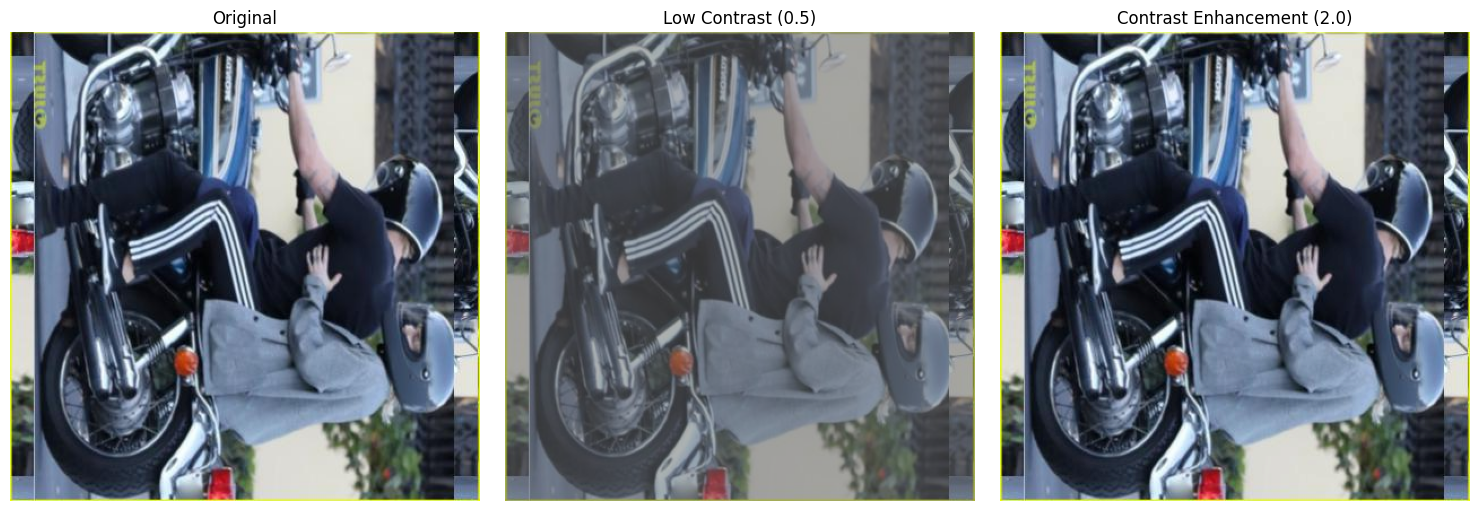

In [13]:
# ดูตัวอย่างภาพ: ต้นฉบับ / ลด Contrast / Contrast Enhancement
import matplotlib.pyplot as plt

sample_path = os.path.join(TRAIN_DIR, "images", selected_files[0])
original = Image.open(sample_path).convert("RGB")
low_contrast = ImageEnhance.Contrast(original).enhance(LOW_CONTRAST)
enhanced = ImageEnhance.Contrast(low_contrast).enhance(ENHANCE)

plt.figure(figsize=(15, 5))
for i, (img, title) in enumerate([
    (original, "Original"),
    (low_contrast, f"Low Contrast ({LOW_CONTRAST})"),
    (enhanced, f"Contrast Enhancement ({ENHANCE})")
], start=1):
    plt.subplot(1, 3, i)
    plt.imshow(img)
    plt.title(title)
    plt.axis("off")
plt.tight_layout()
plt.show()

### Train YOLO11: เปรียบเทียบเทรน 1 รอบ (1 epoch) กับ 10 รอบ (10 epochs)

- ใช้ภาพ Train ที่ปรับ Contrast ชุดเดียวกัน, hyperparameter เดียวกัน ต่างกันแค่จำนวน epoch
- หมายเหตุ: YOLO มี warmup 3 epoch แรก โมเดล 1 epoch จึงยังเรียนรู้ได้น้อยมาก (ใช้เป็นจุดเทียบ)

In [14]:
def train_model(data_yaml, epochs, name):

    model = YOLO("yolo11n.pt")

    model.train(
        data=data_yaml,
        epochs=epochs,
        imgsz=640,
        batch=16,
        seed=42,
        project="/content/runs",
        name=name,
        exist_ok=True
    )

    return f"/content/runs/{name}/weights/best.pt"

In [15]:
# Model A: เทรน 1 รอบ
MODEL_1EP = train_model(DATA_CONTRAST, epochs=1, name="yolo_1epoch")

Ultralytics 8.4.185 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data_contrast.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo_1epoch, nbs=64, nms=None, opset=None, optimize=False, optim

In [16]:
# Model B: เทรน 10 รอบ
MODEL_10EP = train_model(DATA_CONTRAST, epochs=10, name="yolo_10epoch")

Ultralytics 8.4.185 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data_contrast.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo_10epoch, nbs=64, nms=None, opset=None, optimize=False, opt

### กราฟ Training Loss vs Validation Loss

YOLO บันทึกค่าทุก epoch ไว้ใน `results.csv` — Loss รวม = box_loss + cls_loss + dfl_loss
และใช้ mAP50 บน Validation แทน Accuracy (งาน Object Detection วัดด้วย mAP)

In [17]:
import pandas as pd


def load_history(name):

    df = pd.read_csv(f"/content/runs/{name}/results.csv")
    df.columns = df.columns.str.strip()

    df["train_loss"] = df["train/box_loss"] + df["train/cls_loss"] + df["train/dfl_loss"]
    df["val_loss"]   = df["val/box_loss"]   + df["val/cls_loss"]   + df["val/dfl_loss"]

    return df


history_1  = load_history("yolo_1epoch")
history_10 = load_history("yolo_10epoch")

display(history_10[["epoch", "train_loss", "val_loss", "metrics/mAP50(B)", "metrics/mAP50-95(B)"]].round(4))

,epoch,train_loss,val_loss,metrics/mAP50(B),metrics/mAP50-95(B)
0,1,8.3043,7.5518,0.3212,0.1305
1,2,5.7615,19.0119,0.1304,0.0401
2,3,5.3208,10.4623,0.2290,0.0772
3,4,5.1330,6.9793,0.5098,0.1961
4,5,4.6834,7.3574,0.4782,0.1755
5,6,4.3920,6.4376,0.5883,0.2605
6,7,4.2304,6.0576,0.5640,0.2626
7,8,3.9811,5.7792,0.6274,0.2919
8,9,3.7182,6.2701,0.5781,0.2468
9,10,3.6057,5.7477,0.6755,0.3036


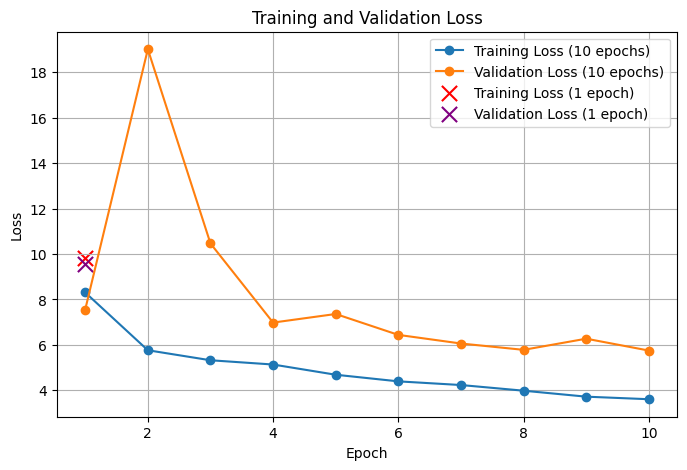

In [18]:
plt.figure(figsize=(8, 5))

plt.plot(history_10["epoch"], history_10["train_loss"], marker="o", label="Training Loss (10 epochs)")
plt.plot(history_10["epoch"], history_10["val_loss"],   marker="o", label="Validation Loss (10 epochs)")

plt.scatter(history_1["epoch"], history_1["train_loss"], s=120, marker="x", c="red",    label="Training Loss (1 epoch)")
plt.scatter(history_1["epoch"], history_1["val_loss"],   s=120, marker="x", c="purple", label="Validation Loss (1 epoch)")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid()
plt.savefig(f"{SAVE_DIR}/loss.png", dpi=150, bbox_inches="tight")
plt.show()

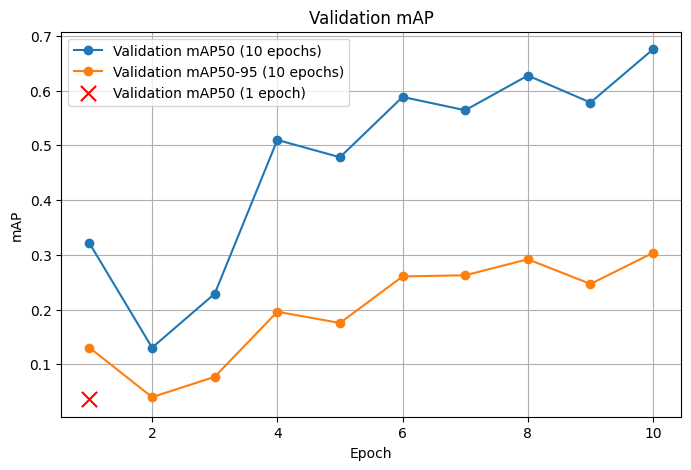

In [19]:
plt.figure(figsize=(8, 5))

plt.plot(history_10["epoch"], history_10["metrics/mAP50(B)"],    marker="o", label="Validation mAP50 (10 epochs)")
plt.plot(history_10["epoch"], history_10["metrics/mAP50-95(B)"], marker="o", label="Validation mAP50-95 (10 epochs)")

plt.scatter(history_1["epoch"], history_1["metrics/mAP50(B)"], s=120, marker="x", c="red", label="Validation mAP50 (1 epoch)")

plt.xlabel("Epoch")
plt.ylabel("mAP")
plt.title("Validation mAP")
plt.legend()
plt.grid()
plt.savefig(f"{SAVE_DIR}/val_map.png", dpi=150, bbox_inches="tight")
plt.show()

In [20]:
# ==============================
# Save YOLO Model to Google Drive (ใช้โมเดล 10 epochs เป็นตัวหลัก)
# ==============================

MODEL_PATH = MODEL_10EP

shutil.copy(MODEL_1EP,  f"{SAVE_DIR}/yolo_1epoch_best.pt")
shutil.copy(MODEL_10EP, f"{SAVE_DIR}/yolo_10epoch_best.pt")

model = YOLO(MODEL_PATH)

print("Model saved to Google Drive!")

Model saved to Google Drive!


In [21]:
# ==============================
# Inference Function (ตรวจ rider + with helmet)
# ==============================

def predict_image(model, image_path, threshold=0.5):

    result = model.predict(
        image_path,
        conf=threshold,
        classes=[RIDER_ID, HELMET_ID],   # ตรวจทั้งคน และคนที่สวมหมวก
        verbose=False
    )[0]

    return result


def count_people(result):
    """นับจากผล predict: คนทั้งหมด / ใส่หมวก / ไม่ใส่หมวก (= คน - ใส่หมวก)"""

    cls = result.boxes.cls.cpu().numpy().astype(int)

    people    = int((cls == RIDER_ID).sum())
    helmet    = int((cls == HELMET_ID).sum())
    no_helmet = max(people - helmet, 0)    # กันค่าติดลบ

    return people, helmet, no_helmet


def count_actual(image_path):
    """นับจากไฟล์ label (คำตอบจริง)"""

    label_path = image_path.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt"
    people, helmet = 0, 0

    if os.path.exists(label_path):
        for line in open(label_path):
            parts = line.split()
            if len(parts) == 5:
                if int(parts[0]) == RIDER_ID:
                    people += 1
                elif int(parts[0]) == HELMET_ID:
                    helmet += 1

    return people, helmet, max(people - helmet, 0)

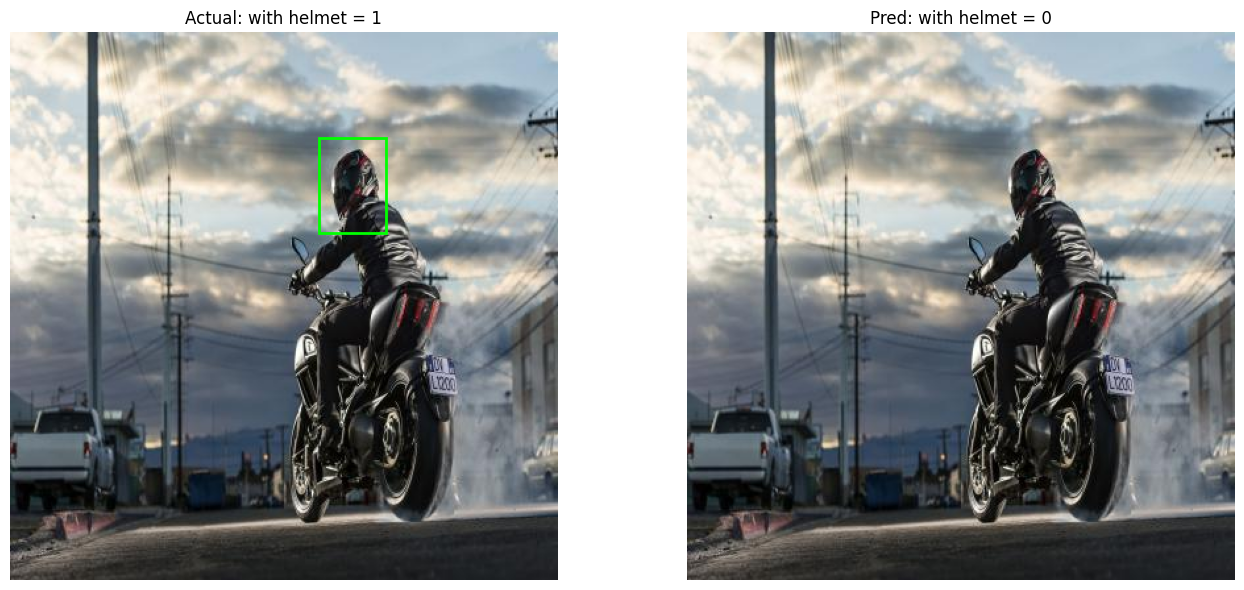

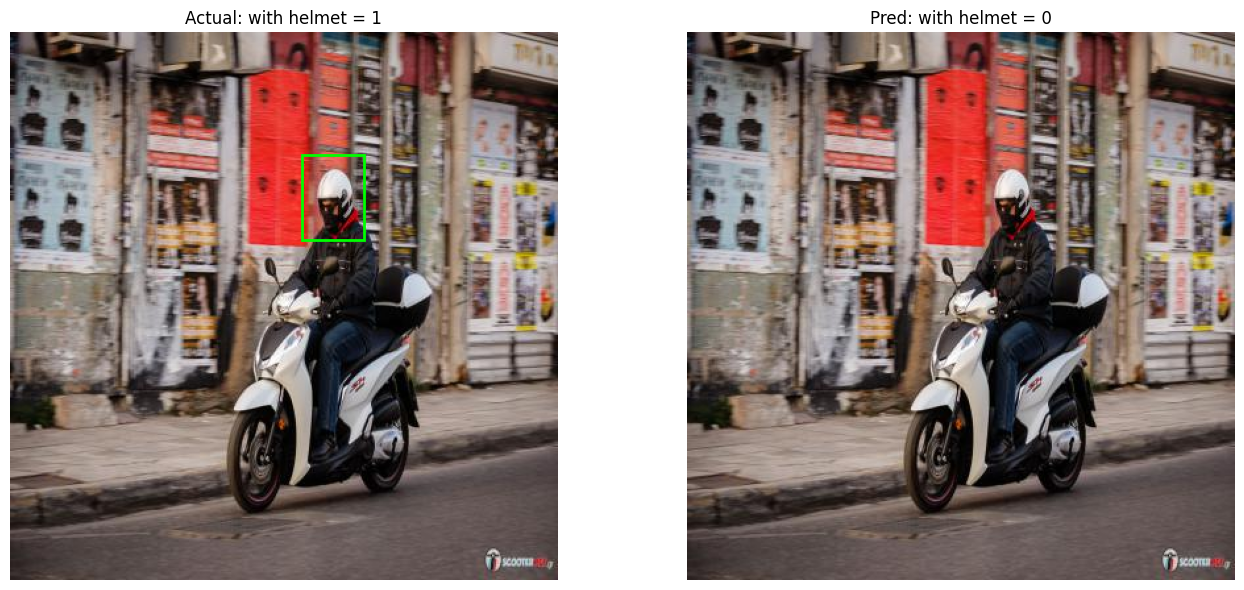

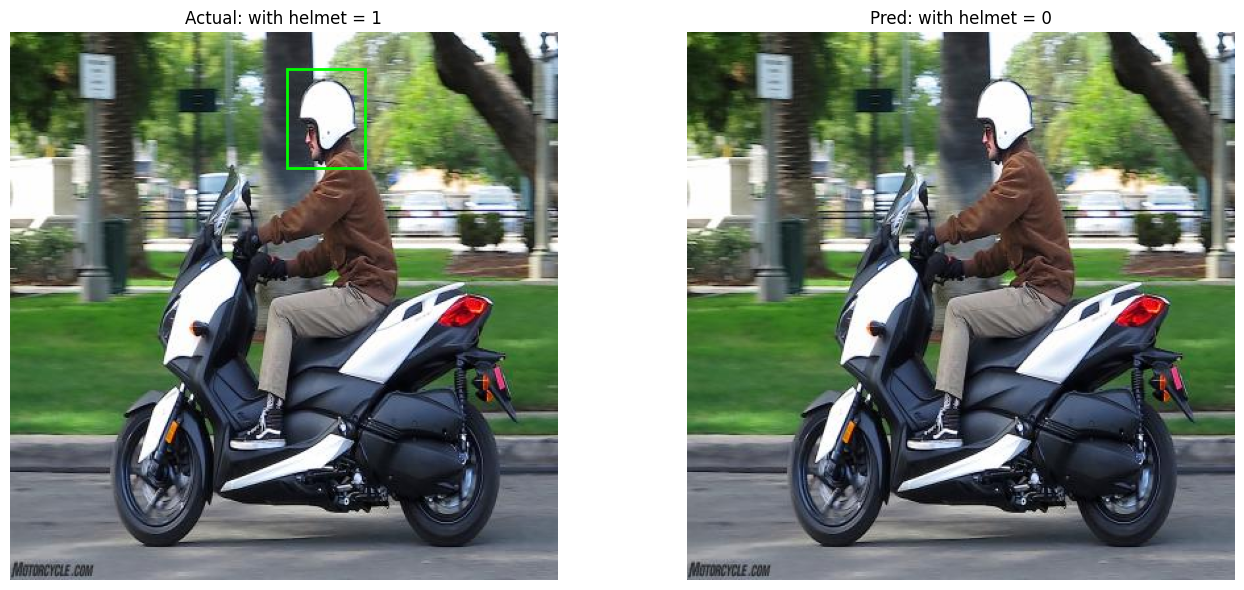

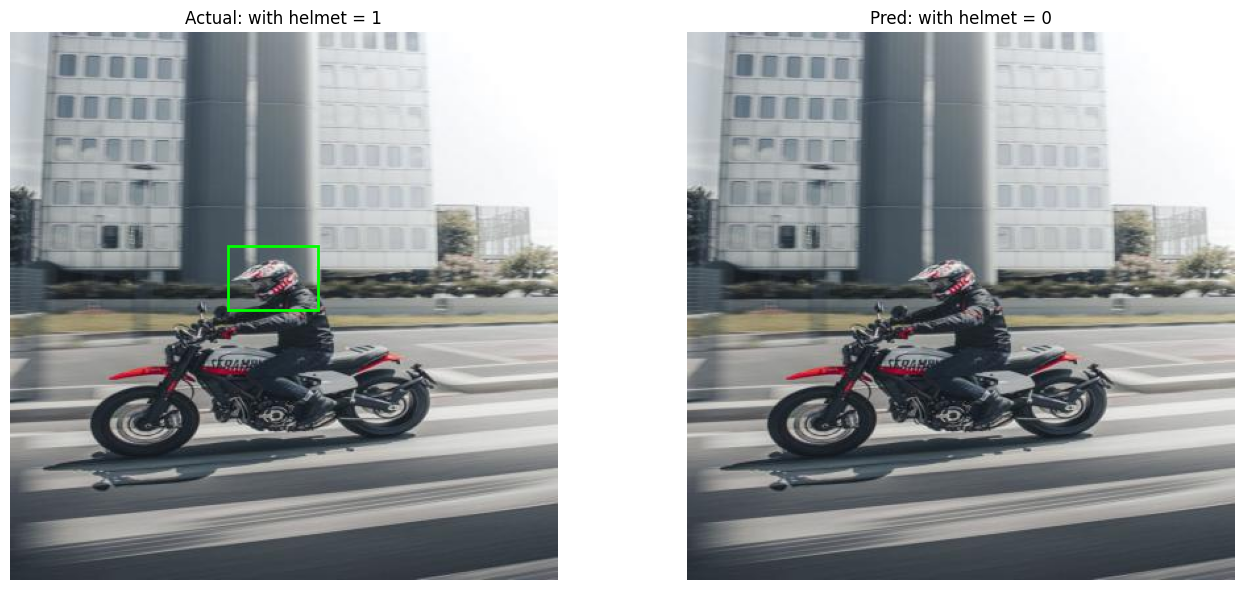

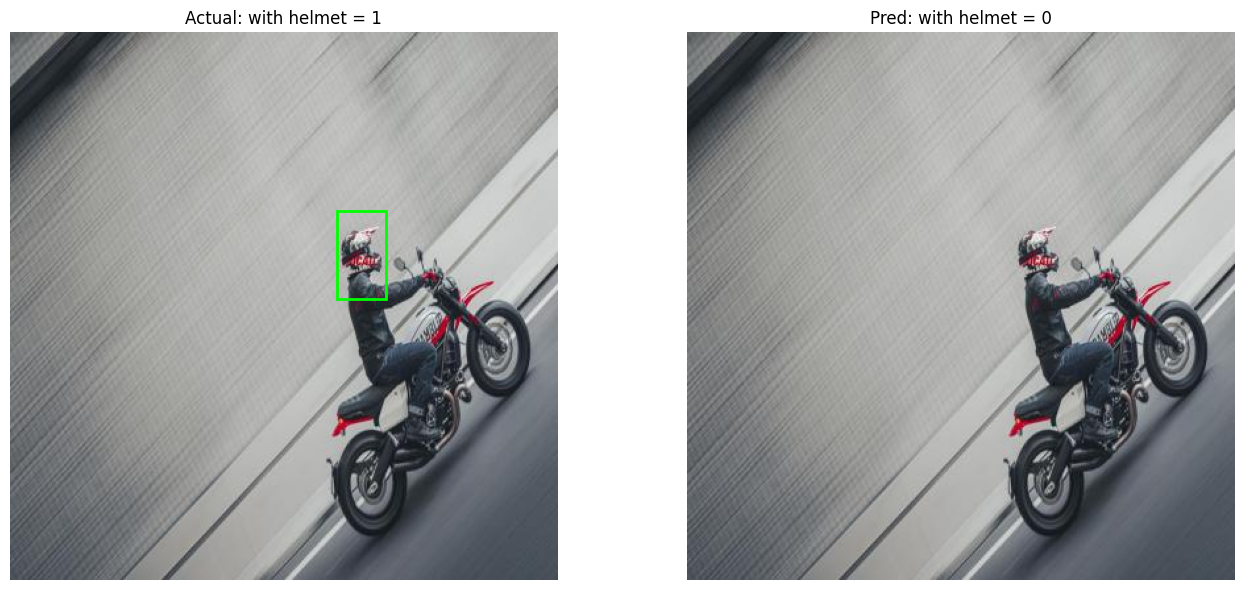

In [22]:
# ==============================
# Predicted vs Actual (Test Images) — แสดงเฉพาะคนที่ใส่หมวก
# ==============================
import matplotlib.patches as patches

NUM_IMAGES = 5

test_images = sorted(os.listdir(os.path.join(TEST_DIR, "images")))


def load_actual_boxes(image_path, w, h):

    label_path = image_path.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt"
    boxes = []

    if os.path.exists(label_path):
        for line in open(label_path):
            parts = line.split()
            if len(parts) == 5 and int(parts[0]) == HELMET_ID:
                cx, cy, bw, bh = map(float, parts[1:])
                boxes.append([(cx - bw / 2) * w, (cy - bh / 2) * h, bw * w, bh * h])

    return boxes


def pred_helmet_boxes(result):

    xyxy = result.boxes.xyxy.cpu().numpy()
    cls  = result.boxes.cls.cpu().numpy().astype(int)
    conf = result.boxes.conf.cpu().numpy()

    return [(b, s) for b, c, s in zip(xyxy, cls, conf) if c == HELMET_ID]


for idx in range(min(NUM_IMAGES, len(test_images))):

    image_path = os.path.join(TEST_DIR, "images", test_images[idx])
    image = Image.open(image_path).convert("RGB")
    w, h = image.size

    actual = load_actual_boxes(image_path, w, h)
    result = predict_image(model, image_path, threshold=0.5)
    pred   = pred_helmet_boxes(result)

    plt.figure(figsize=(14, 6))

    plt.subplot(1, 2, 1)
    plt.imshow(image)
    for x, y, bw, bh in actual:
        plt.gca().add_patch(patches.Rectangle((x, y), bw, bh, fill=False, ec="lime", lw=2))
    plt.title(f"Actual: with helmet = {len(actual)}")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(image)
    for (x1, y1, x2, y2), s in pred:
        plt.gca().add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec="lime", lw=2))
        plt.text(x1, y1 - 4, f"helmet {s:.2f}", color="black", fontsize=9,
                 bbox=dict(facecolor="lime", alpha=.8, pad=1))
    plt.title(f"Pred: with helmet = {len(pred)}")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

### นับจำนวนคน / ใส่หมวก / ไม่ใส่หมวก (Test set ทั้งหมด)

- **ไม่ใส่หมวก = จำนวน rider − จำนวน with helmet** (ถ้าติดลบให้เป็น 0)
- **MAE / image** = นับคลาดจากคำตอบจริงเฉลี่ยกี่คนต่อภาพ (ยิ่งใกล้ 0 ยิ่งดี)
- **Exact match %** = กี่ % ของภาพที่นับได้ตรงเป๊ะ
- ข้อจำกัด: บอกได้แค่ "จำนวน" ไม่ได้บอกว่าคนไหนไม่ใส่หมวก

In [23]:
# ==============================
# Counting Statistics (Test set ทั้งหมด)
# ==============================

rows = []

for fn in test_images:

    image_path = os.path.join(TEST_DIR, "images", fn)
    result = predict_image(model, image_path, threshold=0.5)

    ap, ah, an = count_actual(image_path)
    pp, ph, pn = count_people(result)

    rows.append({
        "image": fn,
        "actual_people": ap, "pred_people": pp,
        "actual_helmet": ah, "pred_helmet": ph,
        "actual_no_helmet": an, "pred_no_helmet": pn,
    })

count_df = pd.DataFrame(rows)

count_summary = pd.DataFrame({
    "Actual (total)": [count_df["actual_people"].sum(), count_df["actual_helmet"].sum(), count_df["actual_no_helmet"].sum()],
    "Pred (total)":   [count_df["pred_people"].sum(),   count_df["pred_helmet"].sum(),   count_df["pred_no_helmet"].sum()],
    "MAE / image": [
        (count_df["actual_people"]    - count_df["pred_people"]).abs().mean(),
        (count_df["actual_helmet"]    - count_df["pred_helmet"]).abs().mean(),
        (count_df["actual_no_helmet"] - count_df["pred_no_helmet"]).abs().mean(),
    ],
    "Exact match %": [
        (count_df["actual_people"]    == count_df["pred_people"]).mean() * 100,
        (count_df["actual_helmet"]    == count_df["pred_helmet"]).mean() * 100,
        (count_df["actual_no_helmet"] == count_df["pred_no_helmet"]).mean() * 100,
    ],
}, index=["People (rider)", "With helmet", "No helmet"])

print("\n========== Counting Result (Test set) ==========")
display(count_summary.round(2))

count_df.to_csv(f"{SAVE_DIR}/test_counts.csv", index=False)
count_summary.to_csv(f"{SAVE_DIR}/count_summary.csv")


========== Counting Result (Test set) ==========


,Actual (total),Pred (total),MAE / image,Exact match %
People (rider),374,291,0.35,80.94
With helmet,417,21,1.32,4.68
No helmet,0,271,0.91,13.71


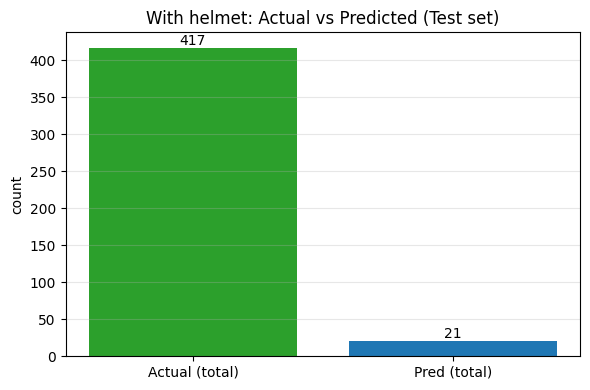

In [24]:
# กราฟเทียบจำนวนคนใส่หมวก Actual vs Predicted
helmet_total = count_summary.loc["With helmet", ["Actual (total)", "Pred (total)"]]

plt.figure(figsize=(6, 4))
bars = plt.bar(helmet_total.index, helmet_total.values, color=["tab:green", "tab:blue"])
plt.bar_label(bars)
plt.ylabel("count")
plt.title("With helmet: Actual vs Predicted (Test set)")
plt.grid(axis="y", alpha=.3)
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/counting.png", dpi=150, bbox_inches="tight")
plt.show()

### ประเมินผลบน Test set: 1 epoch vs 10 epochs

In [25]:
def evaluate(model_path, data_yaml, name):

    results = YOLO(model_path).val(
        data=data_yaml,
        split="test",
        imgsz=640,
        project="/content/runs",
        name=f"{name}_test",
        exist_ok=True
    )

    print(f"\n========== {name} : Test Results ==========")
    print(f"AP50-95 (mAP): {results.box.map:.4f}")
    print(f"AP50         : {results.box.map50:.4f}")
    print(f"AP75         : {results.box.map75:.4f}")
    print(f"AP50-95 [with helmet]: {results.box.maps[HELMET_ID]:.4f}")

    return results


results_1  = evaluate(MODEL_1EP,  DATA_CONTRAST, "yolo_1epoch")
results_10 = evaluate(MODEL_10EP, DATA_CONTRAST, "yolo_10epoch")

Ultralytics 8.4.185 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,537 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1234.9±322.2 MB/s, size: 28.3 KB)
val: Scanning /content/capstone_rider_helmet_RTMS-1/test/labels... 299 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 299/299 1.9Kit/s 0.2s
val: New cache created: /content/capstone_rider_helmet_RTMS-1/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 19/19 3.7it/s 5.1s
                   all        299        792     0.0378      0.409     0.0222    0.00475
            motorcycle          1          1    0.00175          1    0.00275    0.00055
                 rider        296        374      0.106      0.219     0.0568     0.0117
           with helmet        297        417    0.00596    0.00719    0.00705    0.00202
Speed: 2.6ms preprocess, 5.3ms inference,

### Confusion Matrix: ใส่หมวก / ไม่ใส่หมวก (Test set)

ตัดสินทีละคน (rider):
1. **Actual** — rider ใน label เป็น "ใส่หมวก" ถ้ามีกล่อง `with helmet` ที่จุดกึ่งกลางอยู่ในครึ่งบนของกล่อง rider (บริเวณศีรษะ) ไม่มี = "ไม่ใส่หมวก"
2. **Pred** — จับคู่ rider ที่โมเดลหาเจอกับ rider จริง (IoU ≥ 0.5) แล้วใช้กฎเดียวกันกับกล่องหมวกที่โมเดลทาย
3. rider จริงที่โมเดลหาไม่เจอ จะไม่อยู่ในตาราง แต่แสดงจำนวนแยกไว้ด้านล่าง

- แถว = Actual, คอลัมน์ = Predicted
- คำนวณที่ confidence threshold 0.5 (ส่วน mAP คำนวณตามมาตรฐาน COCO ที่ threshold 0.001)

1 epoch: accuracy = 0.0000 | matched riders = 24 | missed riders = 350 | helmet boxes: label = 417, predicted = 62
10 epochs: accuracy = 0.3588 | matched riders = 262 | missed riders = 112 | helmet boxes: label = 417, predicted = 120


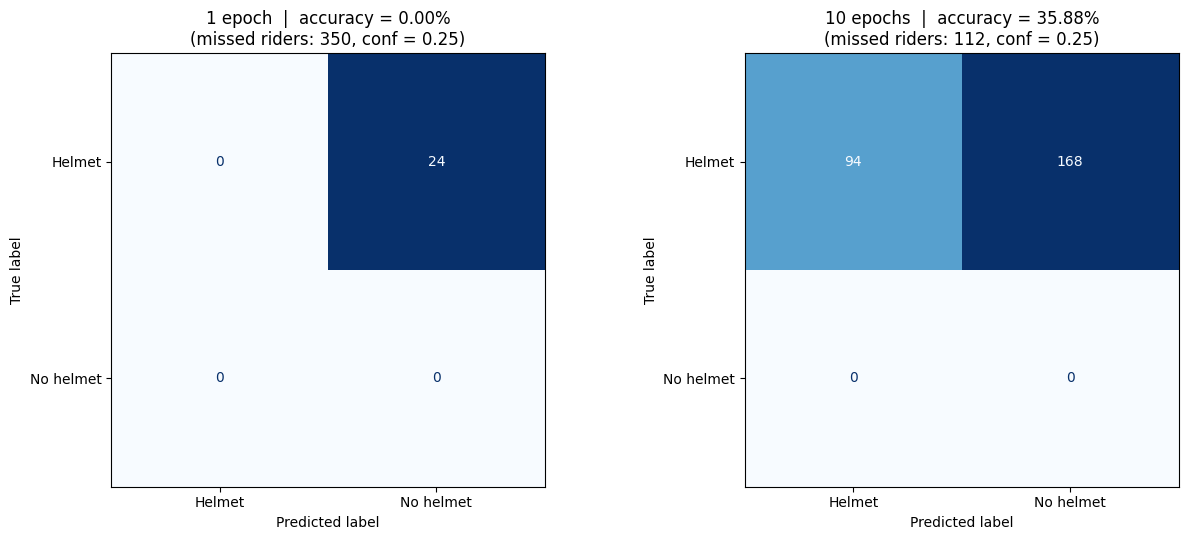

In [29]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

CM_CONF   = 0.25  # confidence threshold (Ultralytics predict default); 0.5 was too strict for this model
IOU_THR   = 0.5   # IoU needed to match a predicted rider with a ground-truth rider
HEAD_PART = 0.5   # top half of the rider box = head region


def label_boxes(image_path, w, h):
    """Read YOLO label file -> {class_id: [[x1, y1, x2, y2], ...]}"""

    label_path = image_path.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt"
    boxes = {RIDER_ID: [], HELMET_ID: []}

    if os.path.exists(label_path):
        for line in open(label_path):
            parts = line.split()
            if len(parts) == 5 and int(parts[0]) in boxes:
                cx, cy, bw, bh = map(float, parts[1:])
                boxes[int(parts[0])].append([(cx - bw / 2) * w, (cy - bh / 2) * h,
                                             (cx + bw / 2) * w, (cy + bh / 2) * h])
    return boxes


def pred_boxes(result):
    """YOLO prediction -> {class_id: [[x1, y1, x2, y2], ...]}"""

    xyxy = result.boxes.xyxy.cpu().numpy()
    cls  = result.boxes.cls.cpu().numpy().astype(int)

    return {RIDER_ID:  [b.tolist() for b, c in zip(xyxy, cls) if c == RIDER_ID],
            HELMET_ID: [b.tolist() for b, c in zip(xyxy, cls) if c == HELMET_ID]}


def wears_helmet(rider, helmets):
    """True if any helmet box has its center inside the head region of the rider box"""

    x1, y1, x2, y2 = rider
    head_bottom = y1 + HEAD_PART * (y2 - y1)
    margin = 0.1 * (y2 - y1)   # allow helmets that stick out slightly above the rider box

    for hx1, hy1, hx2, hy2 in helmets:
        cx, cy = (hx1 + hx2) / 2, (hy1 + hy2) / 2
        if x1 <= cx <= x2 and y1 - margin <= cy <= head_bottom:
            return True

    return False


def iou(a, b):

    ix1, iy1 = max(a[0], b[0]), max(a[1], b[1])
    ix2, iy2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter

    return inter / union if union > 0 else 0


def helmet_confusion(model_path):

    m = YOLO(model_path)
    y_true, y_pred, missed = [], [], 0
    n_gt_helmet, n_pred_helmet = 0, 0

    for fn in test_images:

        image_path = os.path.join(TEST_DIR, "images", fn)
        w, h = Image.open(image_path).size

        gt = label_boxes(image_path, w, h)
        pr = pred_boxes(predict_image(m, image_path, threshold=CM_CONF))

        n_gt_helmet   += len(gt[HELMET_ID])
        n_pred_helmet += len(pr[HELMET_ID])

        used = set()

        for g in gt[RIDER_ID]:

            # find the unused predicted rider with the highest IoU
            best_j, best_iou = -1, IOU_THR
            for j, p in enumerate(pr[RIDER_ID]):
                v = iou(g, p)
                if j not in used and v >= best_iou:
                    best_j, best_iou = j, v

            if best_j < 0:
                missed += 1
                continue

            used.add(best_j)
            y_true.append(wears_helmet(g, gt[HELMET_ID]))
            y_pred.append(wears_helmet(pr[RIDER_ID][best_j], pr[HELMET_ID]))

    cm = confusion_matrix(y_true, y_pred, labels=[True, False])

    return cm, missed, n_gt_helmet, n_pred_helmet


fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

for ax, (model_path, title) in zip(axes, [(MODEL_1EP, "1 epoch"), (MODEL_10EP, "10 epochs")]):

    cm, missed, n_gt_h, n_pr_h = helmet_confusion(model_path)
    acc = cm.trace() / cm.sum() if cm.sum() else 0

    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Helmet", "No helmet"])
    disp.plot(cmap="Blues", ax=ax, colorbar=False, values_format="d")
    ax.set_title(f"{title}  |  accuracy = {acc:.2%}\n(missed riders: {missed}, conf = {CM_CONF})")

    print(f"{title}: accuracy = {acc:.4f} | matched riders = {cm.sum()} | missed riders = {missed} "
          f"| helmet boxes: label = {n_gt_h}, predicted = {n_pr_h}")

plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

### Baseline: เทรน 10 รอบแบบไม่ปรับ Contrast (เปรียบเทียบ Image Processing)

In [30]:
MODEL_BASELINE   = train_model(DATA_BASELINE, epochs=10, name="yolo_baseline_10epoch")
results_baseline = evaluate(MODEL_BASELINE, DATA_BASELINE, "yolo_baseline_10epoch")

Ultralytics 8.4.185 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data_baseline.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo_baseline_10epoch, nbs=64, nms=None, opset=None, optimize=F


========== Experimental Result (Test set) ==========


,"Contrast, 1 epoch","Contrast, 10 epochs","Baseline, 10 epochs"
AP50-95 (mAP),0.0048,0.1863,0.2011
AP50,0.0222,0.4139,0.4242
AP75,0.0003,0.1326,0.1636
Precision,0.0378,0.4767,0.4775
Recall,0.4088,0.4043,0.4045
Helmet Precision,0.0060,0.6123,0.6716
Helmet Recall,0.0072,0.4964,0.4676
Helmet AP50,0.0070,0.5095,0.5290
Helmet AP50-95,0.0020,0.1825,0.1995


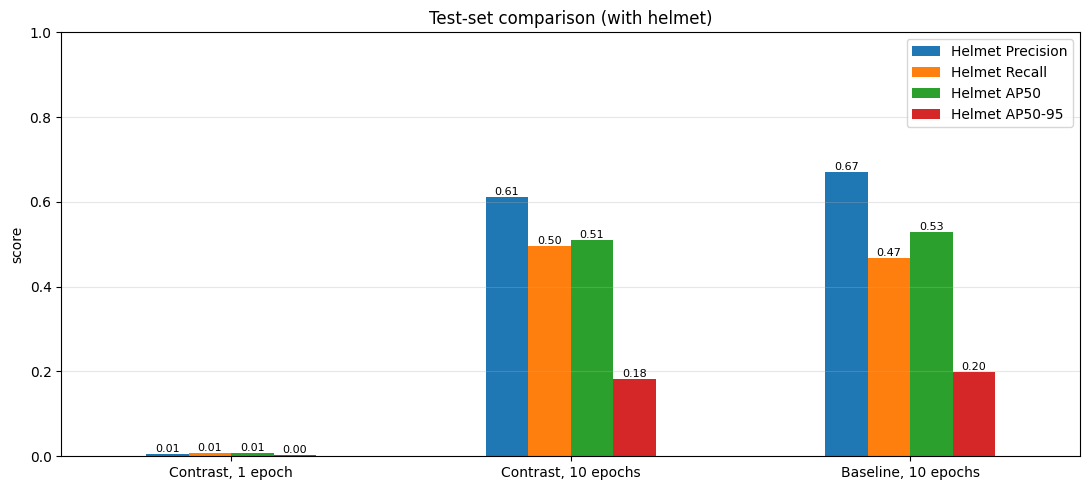

In [31]:
def to_row(res):

    # ค่าเฉพาะคลาส with helmet: class_result(i) คืน (P, R, AP50, AP50-95) ของคลาสลำดับที่ i
    i = list(res.box.ap_class_index).index(HELMET_ID)
    hp, hr, hap50, hap = res.box.class_result(i)

    return [res.box.map, res.box.map50, res.box.map75, res.box.mp, res.box.mr,
            hp, hr, hap50, hap]


compare = pd.DataFrame({
    "Contrast, 1 epoch":   to_row(results_1),
    "Contrast, 10 epochs": to_row(results_10),
    "Baseline, 10 epochs": to_row(results_baseline),
}, index=["AP50-95 (mAP)", "AP50", "AP75", "Precision", "Recall",
          "Helmet Precision", "Helmet Recall", "Helmet AP50", "Helmet AP50-95"])

print("\n========== Experimental Result (Test set) ==========")
display(compare.round(4))

# กราฟแสดงเฉพาะค่าของคลาส with helmet
helmet_rows = ["Helmet Precision", "Helmet Recall", "Helmet AP50", "Helmet AP50-95"]

ax = compare.loc[helmet_rows].T.plot(kind="bar", figsize=(11, 5), rot=0,
                                      title="Test-set comparison (with helmet)")
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", fontsize=8)
plt.ylabel("score")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=.3)
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/comparison.png", dpi=150, bbox_inches="tight")
plt.show()

In [32]:
# ==============================
# Save Results to Google Drive
# ==============================

compare.to_csv(f"{SAVE_DIR}/week1_results.csv")

# โฟลเดอร์ runs มีครบ: best.pt, last.pt, results.csv, กราฟของ YOLO, confusion matrix
shutil.copytree("/content/runs", f"{SAVE_DIR}/runs", dirs_exist_ok=True)

print("All results saved to:", SAVE_DIR)
print(os.listdir(SAVE_DIR))

All results saved to: /content/drive/MyDrive/helmet_week1
['loss.png', 'val_map.png', 'yolo_1epoch_best.pt', 'yolo_10epoch_best.pt', 'test_counts.csv', 'count_summary.csv', 'counting.png', 'confusion_matrix.png', 'comparison.png', 'week1_results.csv', 'runs']
